# Declaración responsable sobre autoría y uso ético de inteligencia artificial, otros recursos o ayuda externa

Con la entrega de esta tarea, declaro de manera responsable que
es el resultado de mi trabajo intelectual personal y creativo, y que ha sido elaborado de acuerdo con los principios éticos y las normas de integridad vigentes en la comunidad académica y, más
específicamente, en la [Universidad Complutense de Madrid](https://www.ucm.es/file/declaracion-responsable-sobre-autoria-y-uso-%C3%89tico-de-herramientas-de-ia).

Soy, pues, autor del material aquí incluido y, cuando no ha sido así y he tomado el material de
otra fuente, lo he citado o bien he declarado su procedencia de forma clara -incluidas, en su
caso, herramientas de inteligencia artificial-. Las ideas y aportaciones principales incluidas en este trabajo, y que acreditan la adquisición de competencias, son mías y no proceden de otras fuentes o han sido reescritas usando material de otras fuentes.

Antes de entregar esta tarea, asegúrate de que todo funcione como se espera:

1. Reinicia el kernel  
   *(En la barra de menú, selecciona **Kernel → Restart**)*  

2. Ejecuta todas las celdas  
   *(En la barra de menú, selecciona **Cell → Run All**)*  

3. Asegúrate de completar todos los lugares donde aparezca:  
   - `YOUR CODE HERE`  
   - `"YOUR ANSWER HERE"`
     
4. Debes borrar las instrucciones que pone `raise NotImplementedError()`

5. Así como tu **nombre** a continuación:

In [ ]:
NOMBRE = ""

## Notas para la entrega

* Se deben rellenar todos los cuadernos sin cambiar el nombre.
* Es impor
* Se debe comprimir la carpeta `tarea_final` en un fichero `.zip`, llamado `tarea_final.zip`.
  
  **Importante**: por favor, no se entreguen ficheros `.rar`.

* Los ficheros CSV son bastante grandes y no son necesario incluirlos. Por eso es **importante** boorrarlos andes de generar el fichero comprimido.
* También es importante borrar los ficheros auxiliares como `*.ipynb_checkpoints`, `.mypy_cache`, `__pycache` y otros fiche.
* Subir el fichero comprimido al campus virtual.

# Ejercicio de Programación en Python: Web Scraping de Datos Abiertos de Madrid

Hasta ahora hemos trabajado siempre con un fichero CSV que ya teníamos descargado. En este cuaderno vamos a construir, paso a paso, el mecanismo para **descargar automáticamente** los ficheros de multas directamente del [Portal de Datos Abiertos del Ayuntamiento de Madrid](https://datos.madrid.es), usando `requests` y `bs4` (BeautifulSoup) — **no está permitido usar Selenium ni ningún otro navegador automatizado**, esto debe resolverse solo con peticiones HTTP y parseo de HTML.

El objetivo final es una función `get_data(year, month)` que, si el fichero `{year}_{month}.csv` ya existe en disco, lo use directamente, y si no, lo busque y descargue de la web. Con eso, montaremos un gráfico de multas mensuales entre dos fechas.

## Cómo encontrar los datos a mano (antes de programar nada)

Antes de escribir código conviene explorar la web con el navegador:

1. Abre <https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/downloads> (la pestaña **"Descargas"** del dataset, no la de "Información").
2. Verás un listado organizado por año y, dentro de cada año, por mes.
3. Si inspeccionas el HTML (botón derecho → Inspeccionar), verás que los datos de cada mes están dentro de un `<div>` con `data-key="{año}-{Mes}"` (por ejemplo `data-key="2026-Enero"`, con el mes en español y con la primera letra en mayúscula). **Ojo:** ese mismo `data-key` aparece más de una vez en la página (hay un índice lateral que lo repite); el bloque que realmente contiene los enlaces de descarga es el que, además, contiene un enlace con un `title` que empieza por `"Detalle"`.
4. Dentro de ese bloque hay más de un recurso disponible para el mismo mes: el que queremos tiene un enlace `<a title="Detalle. Enero 2026">`; hay otro con `<a title="Agrupadas-excluidas. Enero 2026">` que **no** nos interesa (son datos agregados, no el detalle fila a fila).
5. A diferencia de la página de información que usábamos antes, aquí el propio bloque de descarga **ya incluye el enlace directo al CSV**: un botón "Descarga" (`<a class="... resource-type-data" href="...">`) cuyo `href` apunta directamente al fichero, sin necesidad de construir la URL a mano.
6. El contenido del fichero descargado debe decodificarse con el *encoding* `'iso-8859-15'`.

Vamos a programar cada uno de estos pasos como un ejercicio independiente, de forma que puedas comprobarlos uno a uno antes de combinarlos.

---

## Celda de Configuración: Importación de Módulos

Reutilizamos, como en `E2_numpy.ipynb`, la constante `MONTHS` de `E1_analisis_fichero.ipynb` mediante `ipynb.fs.defs`; y también la función `load_dataframe` de `E3_pandas.ipynb` (la usaremos en el Ejercicio 7 en lugar de escribir de nuevo una función de carga). Como ambos nombres de módulo empiezan por una letra, basta con `import ipynb` seguido de `from ipynb.fs.defs.E1_analisis_fichero import MONTHS` y `from ipynb.fs.defs.E3_pandas import load_dataframe`.

Importa en la siguiente celda `requests`, `BeautifulSoup` (de `bs4`), `pandas`, `os`, `doctest`, el módulo `testing`, y `MONTHS`/`load_dataframe` tal y como se explica arriba. En este ejercicio analizaremos el mismo fichero `2023_nov.csv` del que vemos las 10 primeras líneas.


In [ ]:
with open('2023_nov.csv') as f:
    for _ in range(10):
        line = next(f).strip()
        print(line)

Los tests de este cuaderno también están en el fichero `testing.py`, junto a los de los cuadernos anteriores.

In [ ]:
import subprocess
import sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'requests', 'beautifulsoup4', 'ipynb', 'pytest'])

In [ ]:
import pytest
import doctest
import os
import testing_04 as testing

# Tus import aquí
# YOUR CODE HERE
raise NotImplementedError()


SITE = "https://datos.madrid.es"
DOWNLOADS_PATH = "/dataset/210104-0-multas-circulacion-detalle/downloads"

# Tus constantes aquí
# YOUR CODE HERE
raise NotImplementedError()

## Ejercicio 1: Descargar y Parsear una Página Web

Escribe una función con la cabecera `def fetch_dataset_page(url: str) -> BeautifulSoup:` que reciba una URL genérica, haga una petición HTTP con `requests` a esa URL, compruebe que la respuesta ha sido correcta, y devuelva un objeto `BeautifulSoup` construido a partir del HTML de la página (usa el parser `'html.parser'`). La función no debe asumir ninguna URL concreta; se usará después pasándole `SITE + DOWNLOADS_PATH`, pero podría usarse con cualquier otra página.

**Nota:** este ejercicio necesita conexión a Internet real a `datos.madrid.es`; no se puede resolver con datos simulados.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe confirmar que se ha encontrado algún bloque de noviembre de 2023 dentro de la página.

In [ ]:
def check_fetch_dataset_page_result():
    soup = fetch_dataset_page(SITE + DOWNLOADS_PATH)
    print(type(soup))
    print('¿Existen bloques de 2023-Noviembre?', len(soup.find_all(attrs={'data-key': '2023-Noviembre'})))
check_fetch_dataset_page_result()

Comprueba tus doctests

In [ ]:
doctest.run_docstring_examples(fetch_dataset_page, globals(), verbose=True)

Comprueba la calidad del docstring

In [ ]:
help(fetch_dataset_page)

### Comprobación automática del código

In [ ]:
testing.test_fetch_dataset_page(fetch_dataset_page)

In [ ]:
testing.test_fetch_dataset_page_typehints(fetch_dataset_page)

In [ ]:
testing.test_docstring(fetch_dataset_page)

In [ ]:
testing.test_doctests(fetch_dataset_page, globals())

A partir de aquí reutilizamos `SOUP`, calculado con la función que acabas de implementar, en el Ejercicio 2.

In [ ]:
SOUP = fetch_dataset_page(SITE + DOWNLOADS_PATH)
type(SOUP)

## Ejercicio 2: Encontrar el Bloque de Recurso "Detalle" de un Mes

Escribe una función con la cabecera `def find_resource_block(soup: BeautifulSoup, year: int, month: str) -> Tag:` que reciba la página ya parseada (como la de `fetch_dataset_page`), un año y un mes (cadena de 3 letras en inglés, como en `E1_analisis_fichero.ipynb`), y devuelva el `Tag` de BeautifulSoup correspondiente al bloque de recurso `"Detalle"` de ese mes (el elemento con clase `"tracked-resource-item"` que contiene el enlace de descarga).

Pasos:
1. Convierte `month` a su nombre en español, con la primera letra en mayúscula (usa `MONTHS_ES[month].capitalize()`), y construye la clave `f'{year}-{mes}'` (por ejemplo `'2026-Enero'`).
2. Busca **todos** los elementos con ese `data-key` (`soup.find_all(attrs={'data-key': clave})`); recuerda que esa clave aparece repetida en la página (hay un índice lateral que no contiene enlaces), así que debes quedarte con el bloque que sí contiene un enlace `<a>` cuyo `title` empiece por `"Detalle"`. Si no encuentras ninguno, lanza un `ValueError`.
3. Dentro de ese bloque, busca el enlace `<a title=f'Detalle. {mes} {year}'>` exacto (no el de `"Agrupadas-excluidas"`). Si no lo encuentras, lanza un `ValueError`.
4. Devuelve el contenedor `<div class="tracked-resource-item">` al que pertenece ese enlace (usa `.find_parent('div', class_='tracked-resource-item')`).

**Nota:** este ejercicio necesita conexión a Internet real (usa una `soup` obtenida con `fetch_dataset_page`).

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar el identificador del recurso de noviembre de 2023.

In [ ]:
def check_find_resource_block_result():
    block = find_resource_block(SOUP, 2023, 'nov')
    print(block.get('data-resourceid'))
check_find_resource_block_result()

Comprueba tus doctests

In [ ]:
doctest.run_docstring_examples(find_resource_block, globals(), verbose=True)

Comprueba la calidad del docstring

In [ ]:
help(find_resource_block)

### Comprobación automática del código

In [ ]:
testing.test_find_resource_block(find_resource_block, SOUP)

In [ ]:
testing.test_find_resource_block_typehints(find_resource_block)

In [ ]:
testing.test_docstring(find_resource_block)

In [ ]:
testing.test_doctests(find_resource_block, globals())

## Ejercicio 3: Extraer la URL de Descarga Directa

A diferencia del planteamiento anterior, aquí el bloque de recurso (el que devuelve `find_resource_block`) **ya contiene** el enlace de descarga directa: un botón "Descarga" (`<a class="... resource-type-data" href="...">`). Escribe una función con la cabecera `def extract_download_url(resource_block: Tag) -> str:` que reciba ese bloque y devuelva la URL absoluta de descarga.

Pasos:
1. Busca dentro del bloque el enlace con clase `'resource-type-data'` (`resource_block.find('a', class_='resource-type-data')`). Si no lo encuentras, lanza un `ValueError`.
2. Si su `href` empieza por `/` (es una URL relativa), añádele `SITE` delante para obtener la URL absoluta.

Este ejercicio **no necesita conexión a Internet**: se puede probar con un trozo de HTML de ejemplo.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar la URL de descarga directa a partir del bloque de noviembre de 2023.

In [ ]:
def check_extract_download_url_result():
    block = find_resource_block(SOUP, 2023, 'nov')
    print(extract_download_url(block))
check_extract_download_url_result()

Comprueba tus doctests

In [ ]:
doctest.run_docstring_examples(extract_download_url, globals(), verbose=True)

Comprueba la calidad del docstring

In [ ]:
help(extract_download_url)

### Comprobación automática del código

In [ ]:
testing.test_extract_download_url(extract_download_url)

In [ ]:
testing.test_extract_download_url_typehints(extract_download_url)

In [ ]:
testing.test_docstring(extract_download_url)

In [ ]:
testing.test_doctests(extract_download_url, globals())

## Ejercicio 4: Descargar y Guardar el CSV de un Mes

Escribe una función con la cabecera `def download_month_csv(year: int, month: str) -> str:` que combine los tres ejercicios anteriores para descargar el fichero CSV de un mes y guardarlo en disco:

1. Consigue la página con `fetch_dataset_page(SITE + DOWNLOADS_PATH)`.
2. Encuentra el bloque del recurso con `find_resource_block`.
3. Extrae la URL de descarga con `extract_download_url`.
4. Descarga el contenido con `requests`. El fichero que sirve `datos.madrid.es` está codificado en `'iso-8859-15'`, así que **no uses `resp.text`** (que dejaría que `requests` adivinase mal la codificación): usa `resp.content` (los bytes en crudo) y decodifícalos tú mismo con `.decode('iso-8859-15')`. Esto te da un `str` de Python con las tildes de `LUGAR` o `HECHO-BOL` ya correctas.
5. Guarda ese `str` en un fichero llamado `{year}_{month}.csv` (por ejemplo, `2023_nov.csv`), pero esta vez escribiéndolo con codificación `'utf-8'` (no la codificación original del fichero descargado).
6. Devuelve la ruta del fichero guardado.

**Nota:** este ejercicio necesita conexión a Internet real.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar la ruta del fichero descargado y su primera línea (la cabecera).

In [ ]:
def check_download_month_csv_result():
    filepath = download_month_csv(2023, 'dec')
    print(filepath)
    with open(filepath, encoding='utf-8') as f:
        print(f.readline().strip())
check_download_month_csv_result()

Comprueba tus doctests

In [ ]:
doctest.run_docstring_examples(download_month_csv, globals(), verbose=True)

Comprueba la calidad del docstring

In [ ]:
help(download_month_csv)

### Comprobación automática del código

In [ ]:
testing.test_download_month_csv(download_month_csv)

In [ ]:
testing.test_download_month_csv_typehints(download_month_csv)

In [ ]:
testing.test_docstring(download_month_csv)

In [ ]:
testing.test_doctests(download_month_csv, globals())

## Ejercicio 5: `get_data`, con Caché en Disco

Escribe la función principal de este cuaderno, con la cabecera `def get_data(year: int, month: str) -> str:`: si el fichero `{year}_{month}.csv` ya existe en el directorio actual, devuelve directamente su ruta (sin descargar nada); si no existe, lo descarga con `download_month_csv` y devuelve la ruta resultante.

De esta forma, cada mes solo se descarga una vez, y las siguientes veces que se pida se reutiliza el fichero local — igual que ya veníamos haciendo con `2023_nov.csv` en los cuadernos anteriores.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar la ruta de `2023_nov.csv` (ya lo tenemos en disco, así que no debería descargar nada) y la de un mes que aún no tengamos.

In [ ]:
def check_get_data_result():
    print(get_data(2023, 'nov'))
    print(get_data(2024, 'jan'))
check_get_data_result()

Comprueba tus doctests

In [ ]:
doctest.run_docstring_examples(get_data, globals(), verbose=True)

Comprueba la calidad del docstring

In [ ]:
help(get_data)

### Comprobación automática del código

In [ ]:
testing.test_get_data(get_data)

In [ ]:
testing.test_get_data_typehints(get_data)

In [ ]:
testing.test_docstring(get_data)

In [ ]:
testing.test_doctests(get_data, globals())

## Ejercicio 6: Rango de Meses entre Dos Fechas

Antes de poder pedir varios meses seguidos, necesitamos poder enumerarlos. Escribe una función con la cabecera `def month_range(start_year: int, start_month: str, end_year: int, end_month: str) -> list[tuple[int, str]]:` que devuelva la lista de pares `(año, mes)` desde la fecha de inicio hasta la de fin, ambas incluidas, en orden cronológico.

Usa la constante `MONTHS_INT` (definida en la celda de constantes a partir de `MONTHS`, importada de `E1_analisis_fichero.ipynb`) para convertir cada mes en un índice absoluto: `año * 12 + MONTHS_INT[mes]`. Con dos índices así puedes recorrer el rango con un `range` y reconstruir cada `(año, mes)` con `divmod` (o `//` y `%`) entre 12.

Si la fecha de fin es anterior a la de inicio, la función debe lanzar un `ValueError`.

Este ejercicio **no necesita conexión a Internet**.


In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar los meses entre noviembre de 2023 y febrero de 2024.

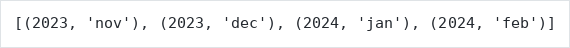

In [ ]:
def check_month_range_result():
    print(month_range(2023, 'nov', 2024, 'feb'))
check_month_range_result()

Comprueba tus doctests

In [ ]:
doctest.run_docstring_examples(month_range, globals(), verbose=True)

Comprueba la calidad del docstring

In [ ]:
help(month_range)

### Comprobación automática del código

In [ ]:
testing.test_month_range(month_range)

In [ ]:
testing.test_month_range_typehints(month_range)

In [ ]:
testing.test_docstring(month_range)

In [ ]:
testing.test_doctests(month_range, globals())

## Ejercicio 7: Todos los Datos en un DataFrame de Pandas

Escribe una función con la cabecera `def download_all_data(start_year: int, start_month: str, end_year: int, end_month: str) -> pd.DataFrame:` que, para cada mes entre las dos fechas (ambas incluidas), obtenga el fichero con `get_data` y lo cargue con `load_dataframe` (la función del Ejercicio 1 de `E3_pandas.ipynb`, no `load_fines_data` de `E1`), y devuelva **un único** `DataFrame` con todas las multas de todos esos meses juntas (usa `pd.concat`, reiniciando el índice).

**Nota:** si alguno de los meses no está ya descargado, este ejercicio necesitará conexión a Internet.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar la forma del `DataFrame` combinado de noviembre y diciembre de 2023.

In [ ]:
def check_download_all_data_result():
    df = download_all_data(2023, 'nov', 2023, 'dec')
    print(df.shape)
    print(df['DENUNCIANTE'].value_counts())
check_download_all_data_result()

Comprueba tus doctests

In [ ]:
doctest.run_docstring_examples(download_all_data, globals(), verbose=True)

Comprueba la calidad del docstring

In [ ]:
help(download_all_data)

### Comprobación automática del código

In [ ]:
testing.test_download_all_data(download_all_data)

In [ ]:
testing.test_download_all_data_typehints(download_all_data)

In [ ]:
testing.test_docstring(download_all_data)

In [ ]:
testing.test_doctests(download_all_data, globals())

A partir de aquí reutilizamos `ALL_DATA`, calculado con la función que acabas de implementar, en el Ejercicio 8.

In [ ]:
ALL_DATA = download_all_data(2023, 'nov', 2023, 'dec')
ALL_DATA.shape

## Ejercicio 8: Gráfico de Tarta por Denunciante

Escribe una función con la cabecera `def plot_complainant_pie(df: pd.DataFrame) -> None:` que reciba un `DataFrame` como el de `download_all_data` y muestre un **gráfico de tarta** con el porcentaje de multas de cada tipo de denunciante (`DENUNCIANTE`). El gráfico debe tener título y mostrar el porcentaje de cada porción. Las porciones deben estar ordenadas en sentido anti-horario.

Como hay denunciantes con porcentajes muy pequeños, **no pongas los nombres directamente sobre las porciones** (se pegan unos a otros); usa una leyenda aparte (`plt.legend`) para los nombres, y evita mostrar el porcentaje de las porciones casi nulas para que no se solape (por ejemplo, con una función para `autopct` que devuelva `''` por debajo de un umbral). La salida debe ser similar a la siguiente:

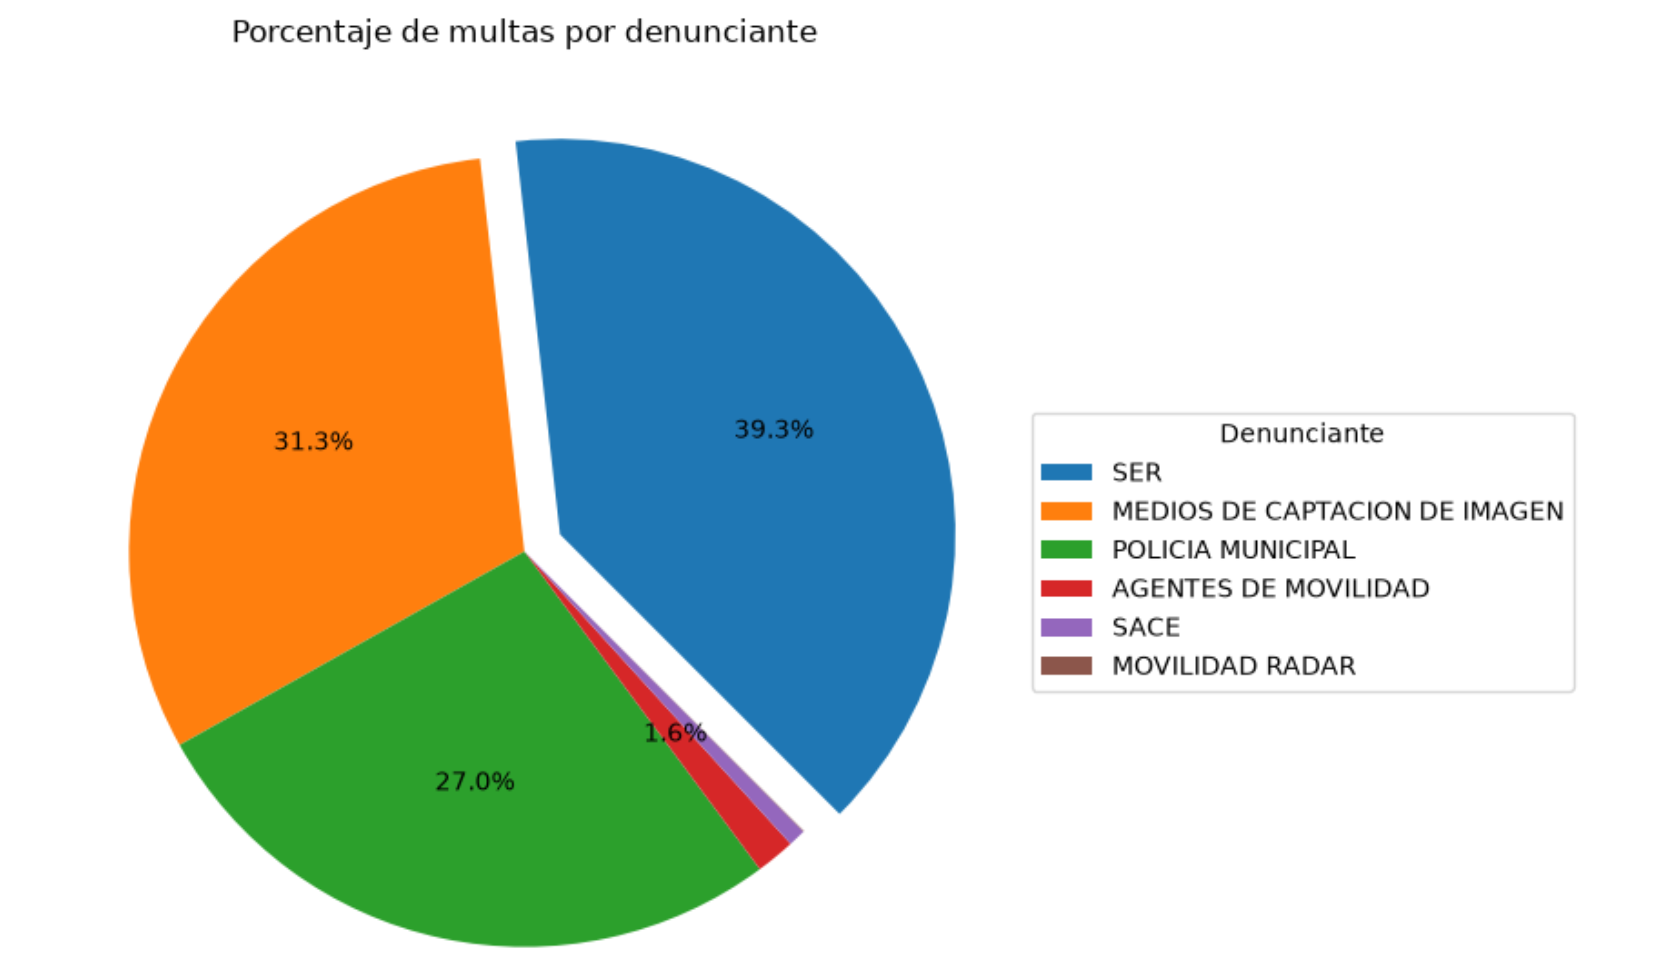

**Este ejercicio se corrige de forma manual** (4 puntos). Asegúrate de que la celda de la solución, al ejecutarla, muestra el gráfico terminado (llama a tu función al final de la misma celda, usando `ALL_DATA`).

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

**Criterios de corrección manual:**
- Usa la columna `DENUNCIANTE` de `ALL_DATA` (o un cálculo equivalente) para contar las multas por denunciante.
- El gráfico es un gráfico de tarta (`plt.pie` u otro equivalente).
- Tiene título; los nombres de los denunciantes están en una leyenda aparte (no pegados a las porciones).
- Muestra el porcentaje de cada porción, sin que los textos se solapen entre sí.
- Los datos representados son correctos (coinciden con los recuentos de `ALL_DATA`).
- Las porciones están ordenadas en sentido antihorario.


## Comprobación final antes de entregar

**Guarda el cuaderno ahora (Ctrl+S / Cmd+S)** y, después, ejecuta la siguiente casilla. Comprueba que no haya identificadores de celda duplicados (algo que suele pasar al copiar una celda de solución o de test en vez de escribir en la tuya propia).

In [ ]:
testing.check_duplicated_ids('E4_webscrapping.ipynb')